In [1]:
import pandas as pd
import matplotlib.pyplot as plt

# Import the employees Excel file
csv_df = pd.read_excel(r"C:\Users\wsher\Downloads\employees (1).csv.xlsx")

# Display the first five rows
print(csv_df.head())

  First Name  Gender Start Date Last Login Time  Salary  Bonus %  \
0    Douglas    Male 1993-08-06        12:42:00   97308    6.945   
1     Thomas    Male 1996-03-31        06:53:00   61933    4.170   
2      Maria  Female 1993-04-23        11:17:00  130590   11.858   
3      Jerry    Male 2005-03-04        13:00:00  138705    9.340   
4      Larry    Male 1998-01-24        16:47:00  101004    1.389   

   Senior Management             Team  
0                1.0        Marketing  
1                1.0              NaN  
2                0.0          Finance  
3                1.0          Finance  
4                1.0  Client Services  


In [2]:
print(csv_df.columns)

Index(['First Name', 'Gender', 'Start Date', 'Last Login Time', 'Salary',
       'Bonus %', 'Senior Management', 'Team'],
      dtype='object')


In [ ]:
Task 1

In [3]:
# Convert Team to a categorical variable
csv_df["Team"] = csv_df["Team"].astype("category")

# Count the number of employees in each Team
print(csv_df["Team"].value_counts())

Team
Client Services         106
Finance                 102
Business Development    101
Marketing                98
Product                  95
Sales                    94
Engineering              92
Human Resources          91
Distribution             90
Legal                    88
Name: count, dtype: int64


In [ ]:
Task 2 

In [4]:
# Group Salary and Team and calculate the average salary
teams_salaries = csv_df[["Salary", "Team"]].groupby("Team")["Salary"].mean()

# Display the average salary for each Team
print(teams_salaries)

Team
Business Development    91866.316832
Client Services         88224.424528
Distribution            88500.466667
Engineering             94269.195652
Finance                 92219.480392
Human Resources         90944.527473
Legal                   89303.613636
Marketing               90435.591837
Product                 88665.505263
Sales                   92173.436170
Name: Salary, dtype: float64


C:\Users\wsher\AppData\Local\Temp\ipykernel_23716\2639445193.py:2: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  teams_salaries = csv_df[["Salary", "Team"]].groupby("Team")["Salary"].mean()


In [5]:
# Replace each Salary with the average salary for that employee's Team
csv_df["Salary"] = csv_df["Team"].map(teams_salaries)

# Display the results
print(csv_df[["Team", "Salary"]].head())

              Team        Salary
0        Marketing  90435.591837
1              NaN           NaN
2          Finance  92219.480392
3          Finance  92219.480392
4  Client Services  88224.424528


In [ ]:
Task 3

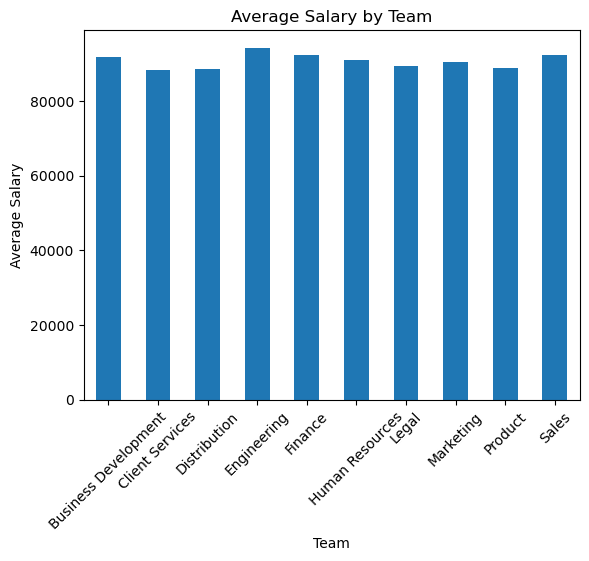

In [6]:
teams_salaries.plot(kind="bar")

plt.xlabel("Team")
plt.ylabel("Average Salary")
plt.title("Average Salary by Team")
plt.xticks(rotation=45)
plt.show()

In [ ]:
Task 4:

In [7]:
# Convert Start Date to DateTime
csv_df["Start Date"] = pd.to_datetime(csv_df["Start Date"])

# Display the first five dates
print(csv_df["Start Date"].head())

0   1993-08-06
1   1996-03-31
2   1993-04-23
3   2005-03-04
4   1998-01-24
Name: Start Date, dtype: datetime64[ns]


In [ ]:
Task 5:

In [10]:
# Create a time series using Start Date and Bonus %
bonus_time_series = pd.Series(
    csv_df["Bonus %"].values,
    index=csv_df["Start Date"]
)

# Display the time series
print(bonus_time_series.head())

Start Date
1993-08-06     6.945
1996-03-31     4.170
1993-04-23    11.858
2005-03-04     9.340
1998-01-24     1.389
dtype: float64


In [ ]:
Task 6:

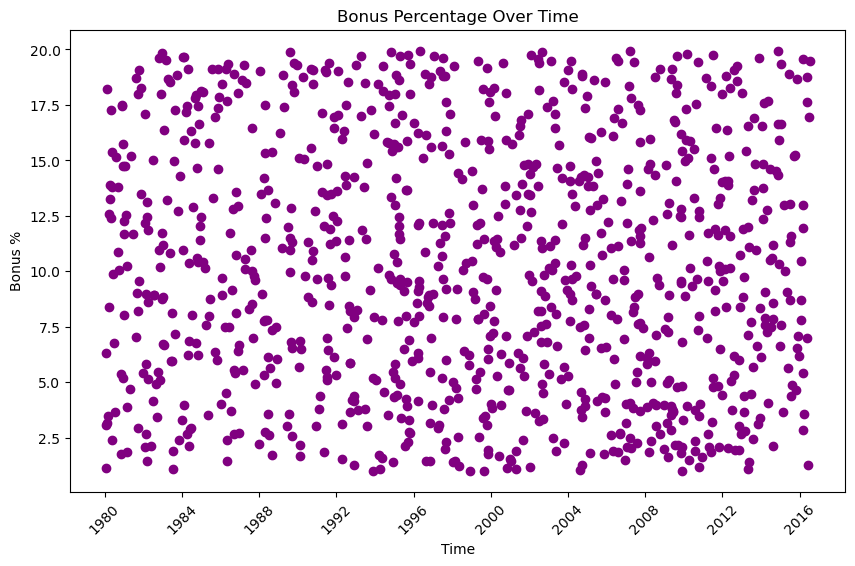

In [11]:
plt.figure(figsize=(10, 6))

plt.scatter(
    bonus_time_series.index,
    bonus_time_series.values,
    color="purple",
    marker="o"
)

plt.xlabel("Time")
plt.ylabel("Bonus %")
plt.title("Bonus Percentage Over Time")
plt.xticks(rotation=45)

plt.show()

In [ ]:
Task 7:

In [12]:
# Find bonus values before January 1, 2008
before_2008 = bonus_time_series[
    bonus_time_series.index < "2008-01-01"
]

print(before_2008)

Start Date
1993-08-06     6.945
1996-03-31     4.170
1993-04-23    11.858
2005-03-04     9.340
1998-01-24     1.389
               ...  
1991-02-10     3.794
1987-07-24    10.982
2002-08-25    11.051
1997-05-15    19.040
1984-01-31    19.675
Length: 753, dtype: float64


In [ ]:
Task 8: 

In [13]:
# Downsample the time series into 3-month intervals
three_month_bonus = bonus_time_series.resample("3ME").mean()

print(three_month_bonus)

Start Date
1980-01-31     3.507000
1980-04-30    10.426857
1980-07-31    10.192750
1980-10-31    12.474500
1981-01-31    11.314000
                ...    
2015-07-31    10.327500
2015-10-31    10.002500
2016-01-31     9.347143
2016-04-30     9.394667
2016-07-31    13.511167
Freq: 3ME, Length: 147, dtype: float64
